In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import sympy as sp
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from scipy import integrate
from functions import Euler

In [3]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Numerically solving the equation:

$$ u_t + vu_x = 0$$
where $ v = v(x,t) $.

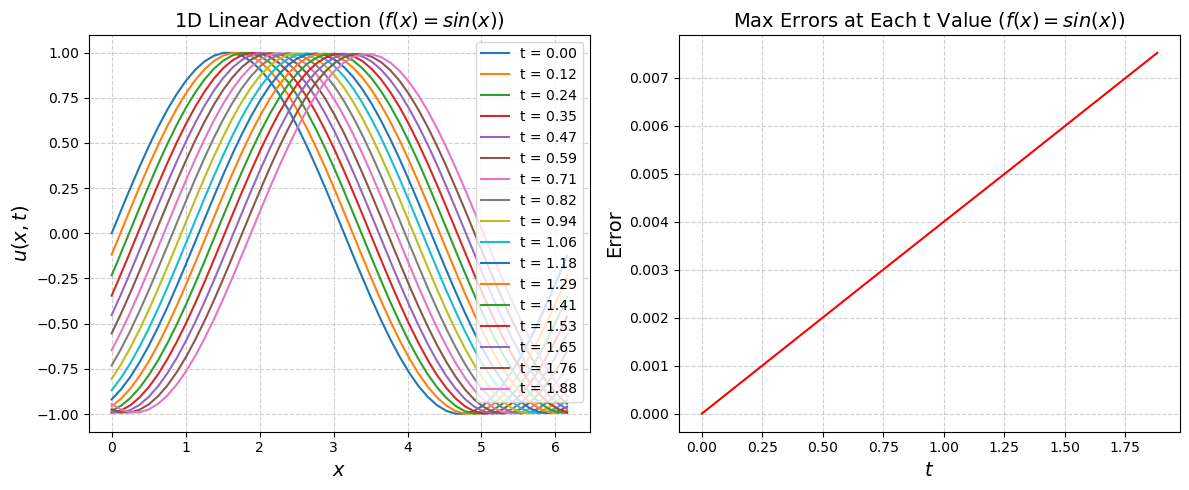

In [4]:
### Initial Condition 1 ###

# Set up x points
L = 2*np.pi
N = 50
x = np.linspace(0, L, N, endpoint = False)

# IC for u is a sine wave
u0 = np.sin(x)

# Constant velocity field
def v(t, x):
    return 1

# Time discretization (CFL condition)
t_start = 0.0
t_end = 2
CFL = 0.9
delta_x = L / N
delta_t = CFL * delta_x / abs(v(0,0))
num_steps = int((t_end- t_start) / delta_t)
t = np.linspace(t_start, t_end, num_steps, endpoint=False)

# Solve PDE
u = Euler(u0, v, t, x)

# Error
u_exact = np.sin(x[None, :] - t[:, None])
error = np.abs(u-u_exact)
max_errors = np.max(error, axis=1)

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
    ax1.plot(x, u[i], label=f"t = {t[i]:.2f}")
#ax1.plot(x, u_exact[50], label=f"t = {t[5]:.2f}")
ax1.set_title(r"1D Linear Advection $(f(x) = sin(x))$", fontsize=14)
ax1.set_ylabel(r"$u(x,t)$", fontsize=14)
ax1.set_xlabel(r"$x$", fontsize=14)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(t, max_errors, color='r')
ax2.set_title(r"Max Errors at Each t Value $(f(x) = sin(x))$", fontsize=14)
ax2.set_ylabel("Error", fontsize=14)
ax2.set_xlabel(r"$t$", fontsize=14)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [5]:
%%capture

fig, ax = plt.subplots(figsize=(8,5))
line, = ax.plot(x, u[0], lw=2)
#ax.set_title("Animated 1D Linear Advection (Upwind Scheme)")
ax.set_xlabel("x")
ax.set_ylabel("u(x,t)")
plt.grid(True, linestyle="--", alpha=0.6)
time_text = ax.text(0.02, 0.9, '', transform=ax.transAxes)

# Update function for animation
def update(frame):
    line.set_ydata(u[frame])
    time_text.set_text(f"t = {t[frame]:.2f}")
    return line, time_text

# Make animation
ani = FuncAnimation(fig, update, frames=len(t), interval=50, blit = True)

plt.show()

In [6]:
HTML(ani.to_html5_video())

In [7]:


# Set up x points
L = 10
N = 50
x = np.linspace(0, L, N, endpoint = False)

# IC for u is x^2
u0 = x**2

# Velocity field
def v(t, x):
    return t - x**2

# Work out the maximum value of v
t_start = 0.0
t_end = 0.1
t_test = np.arange(t_start, t_end, 0.01)
v_values = np.zeros(len(x)*len(t_test))
k = 0
for i in t_test:
    for j in x:
        v_values[k] = abs(v(i,j))
        k += 1
v_max = np.max(v_values)

# Time discretization (CFL condition)
CFL = 0.1
delta_x = L / N
delta_t = CFL * delta_x / v_max
num_steps = int((t_end - t_start) / delta_t)
t = np.linspace(t_start, t_end, num_steps, endpoint=False)

# Solve PDE
u = Euler(u0, v, t, x)

# Plot results
#plt.figure(figsize=(8,5))
#for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
#    plt.plot(x, u[i], label=f"t = {t[i]:.2f}")

#plt.title("1D Linear Advection (Upwind Euler Scheme)")
#plt.xlabel("x")
#plt.ylabel("u(x,t)")
#plt.legend()
#plt.grid(True, linestyle="--", alpha=0.6)
#plt.show()

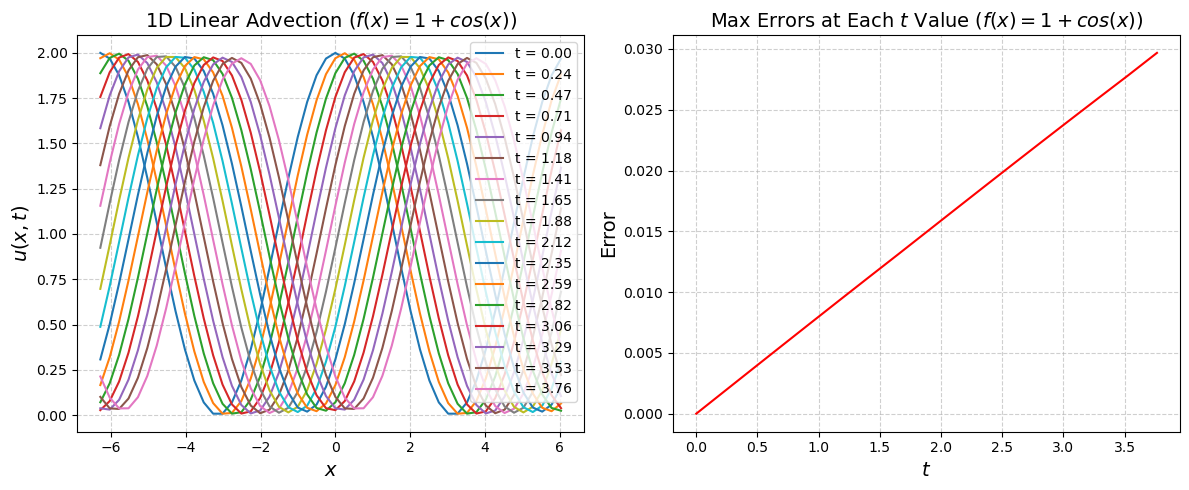

In [9]:
### Initial Condition 2 ###

# Set up x points
L = 2*np.pi
N = 50
x = np.linspace(-L, L, N, endpoint = False)

# IC for u
u0 = 1 + np.cos(x)

# Constant velocity field
def v(t, x):
    return 1.0

# Time discretization (CFL condition)
t_start = 0.0
t_end = 4.0
CFL = 0.9
delta_x = 2*L / N
delta_t = CFL * delta_x / abs(np.max(v(t,x)))
num_steps = int((t_end - t_start) / delta_t)
t = np.linspace(t_start, t_end, num_steps, endpoint=False)

# Solve PDE
u = Euler(u0, v, t, x)

# Error
u_exact = 1 + np.cos(x[None, :] - v(t, x) * t[:, None])
error = np.abs(u-u_exact)
max_errors = np.max(error, axis=1)

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for i in range(0, len(t), len(t)//10):   # plot ~10 snapshots
    ax1.plot(x, u[i], label=f"t = {t[i]:.2f}")
ax1.set_title(r"1D Linear Advection $(f(x) = 1 + cos(x))$", fontsize = 14)
ax1.set_xlabel(r"$x$", fontsize = 14)
ax1.set_ylabel(r"$u(x,t)$", fontsize = 14)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(t, max_errors, color='r')
ax2.set_title(r"Max Errors at Each $t$ Value $(f(x) = 1 + cos(x))$", fontsize = 14)
ax2.set_xlabel(r"$t$", fontsize = 14)
ax2.set_ylabel("Error", fontsize = 14)
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

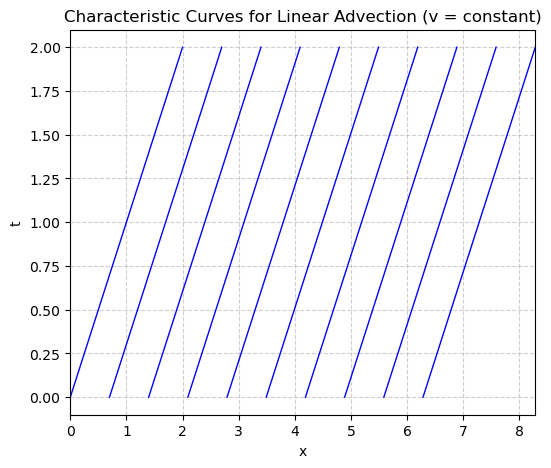

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
v = 1.0                # constant velocity
L = 2*np.pi
x0 = np.linspace(0, L, 10)   # initial positions
t = np.linspace(0, 2, 200)   # time range

# Plot
plt.figure(figsize=(6,5))

for xi in x0:
    x = xi + v * t
    plt.plot(x, t, 'b', lw=1)

# Formatting
plt.xlabel("x")
plt.ylabel("t")
plt.title("Characteristic Curves for Linear Advection (v = constant)")
plt.xlim(0, L + v*max(t))
plt.grid(True, linestyle="--", alpha=0.6)

plt.show()